# Лабораторная работа №2
## Рекомендательные системы: персональные рекомендации книг

**Цель.** Построить и сравнить персональные top-$10$ рекомендации книг на положительных пользовательских взаимодействиях, проверить данные, выполнить строгую временную offline-оценку и объяснить компромисс между точностью и свойствами списка рекомендаций.

### Паспорт эксперимента

| Компонент | Решение |
| --- | --- |
| Данные | [UCSD Book Graph / Goodreads, Comics & Graphic](https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/UCSD%20Book%20Graph.html) |
| Положительный сигнал | `is_read=True` и рейтинг $\geq4$ |
| Время сигнала | `date_added`: момент, когда положительная shelf-запись стала наблюдаемой системе |
| `read_at` и `date_updated` | Используются только для QA/EDA, не для temporal order: `read_at` неполон и может быть self-reported задним числом, `date_updated` — время редактирования |
| Дедупликация | Для повторной положительной пары user–book остаётся первое наблюдение по `(date_added, book_id)` |
| Outer test | Глобальный timestamp-block cutoff: train `< T_outer`, future `≥ T_outer`; цель — единственная первая future-книга пользователя |
| Inner validation | Независимый global cutoff внутри outer-train; применяется только при выборе регуляризации EASE |
| Каталог | 800 самых популярных книг **только из соответствующего train**; после построения не меняется |
| Оцениваемая область | Warm users: не менее 3 prior in-catalog книг; singleton first-future target внутри fixed warm catalog |
| Метрики | Recall@10, NDCG@10, MRR@10, Novelty@10, Diversity@10, Coverage@10 |

**Область применимости.** Это оценка предсказания следующего наблюдаемого **положительного добавления на полку**, а не подтверждённого следующего завершённого чтения. Она относится только к warm users и warm items фиксированного head-каталога, не к cold-start и не ко всему long tail.

Исходные файлы загружаются только локально в игнорируемый Git каталог `data/raw/`. В репозиторий включён лишь [manifest](data_manifest.json): URL, размер и SHA-256 проверенной версии файлов.


## 1. Библиотеки, параметры, provenance и загрузка

Для воспроизводимости загрузка атомарна, а локальные файлы проверяются по размеру и SHA-256 из `data_manifest.json`. Изменение исходного датасета требует осознанного обновления manifest, а не тихой подмены входных данных.

In [1]:
from __future__ import annotations

import gzip
import hashlib
import json
import math
import os
import shutil
import urllib.request
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12

# Supports launching from either repository root or this lab directory.
_candidates = (Path.cwd(), Path.cwd() / "labs" / "lab2-book-recommenders")
LAB_DIR = next((candidate for candidate in _candidates if (candidate / "requirements.txt").is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Run from the repository root or labs/lab2-book-recommenders.")

DATA_DIR = LAB_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = LAB_DIR / "data_manifest.json"
MANIFEST = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

USER_SAMPLE_PERCENT = 5
MIN_USER_RAW_INTERACTIONS = 5
MIN_TRAIN_INTERACTIONS = 3
N_CATALOG_ITEMS = 800
K = 10
EASE_CANDIDATES = (50.0, 100.0, 300.0, 600.0, 1000.0)
MIN_EVENT_YEAR = 1900
MAX_EVENT_YEAR = 2020


def sha256sum(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for block in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_source_file(spec: dict[str, object]) -> Path:
    path = RAW_DIR / str(spec["filename"])
    expected_size = int(spec["size_bytes"])
    expected_hash = str(spec["sha256"])
    valid = path.is_file() and path.stat().st_size == expected_size and sha256sum(path) == expected_hash
    if not valid:
        temporary = path.with_suffix(path.suffix + ".part")
        temporary.unlink(missing_ok=True)
        print(f"Скачивание {spec['url']}")
        try:
            with urllib.request.urlopen(str(spec["url"])) as response, temporary.open("wb") as target:
                shutil.copyfileobj(response, target)
            if temporary.stat().st_size != expected_size or sha256sum(temporary) != expected_hash:
                raise ValueError(f"Проверка размера или SHA-256 не пройдена для {path.name}")
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)
    print(f"Проверен источник: {path.name}; SHA-256={expected_hash[:12]}…")
    return path


INTERACTIONS_PATH = ensure_source_file(MANIFEST["files"]["interactions"])
BOOKS_PATH = ensure_source_file(MANIFEST["files"]["books"])
pd.DataFrame([
    {"Файл": name, "Размер, MiB": round(int(spec["size_bytes"]) / 2**20, 1), "SHA-256": str(spec["sha256"])}
    for name, spec in MANIFEST["files"].items()
])

Проверен источник: goodreads_interactions_comics_graphic.json.gz; SHA-256=b55fbe66c2c8…
Проверен источник: goodreads_books_comics_graphic.json.gz; SHA-256=f55217fa4aa6…


,Файл,"Размер, MiB",SHA-256
0,interactions,369.5,b55fbe66c2c802cefad5051808724d5074e342d6a40043...
1,books,65.6,f55217fa4aa6f615a5a22ffba0e2bba8706f650cff49af...


## 2. Исходные данные и контроль качества

Полный файл взаимодействий проходит потоковый аудит обязательных полей и диапазона рейтинга до отбора строк. Затем детерминированная 5%-подвыборка пользователей задаётся хешем ID — порядок строк источника на отбор не влияет. Проверка семантики и правдоподобия `date_added` выполняется для выбранных положительных строк: именно они становятся входом модели.

Для temporal protocol используется только `date_added`: это полный timestamp появления shelf-записи в наблюдаемом датасете. `read_at` существует не для всех записей и может предшествовать `date_added`, когда пользователь добавил историческое чтение задним числом. `date_updated` — timestamp редактирования. Оба поля анализируются, но не создают искусственную последовательность событий.


In [2]:
TIME_FORMAT = "%a %b %d %H:%M:%S %z %Y"


def chosen_user(user_id: str) -> bool:
    digest = hashlib.blake2b(user_id.encode("utf-8"), digest_size=8).digest()
    return int.from_bytes(digest, "big") % 100 < USER_SAMPLE_PERCENT


def parse_time(value: object) -> pd.Timestamp | pd.NaT:
    if not value:
        return pd.NaT
    return pd.to_datetime(value, format=TIME_FORMAT, errors="coerce", utc=True)


def parse_and_audit(path: Path) -> tuple[pd.DataFrame, pd.Series]:
    rows: list[dict[str, object]] = []
    audit = Counter({
        "Пропуски user_id": 0,
        "Пропуски book_id": 0,
        "Не числовой рейтинг": 0,
        "Рейтинг вне диапазона [0, 5]": 0,
        "Положительные записи без корректного date_added": 0,
        f"Положительные записи с date_added вне [{MIN_EVENT_YEAR}, {MAX_EVENT_YEAR}]": 0,
    })
    selected_users: set[str] = set()
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            audit["Строк в исходном файле"] += 1
            record = json.loads(line)
            user_id = record.get("user_id")
            book_id = record.get("book_id")
            rating = record.get("rating")
            if not user_id:
                audit["Пропуски user_id"] += 1
            if not book_id:
                audit["Пропуски book_id"] += 1
            if not isinstance(rating, (int, float)):
                audit["Не числовой рейтинг"] += 1
            elif not 0 <= rating <= 5:
                audit["Рейтинг вне диапазона [0, 5]"] += 1
            if record.get("is_read") is True:
                audit["Прочитанные записи"] += 1
            if isinstance(rating, (int, float)) and rating > 0:
                audit["Записи с рейтингом"] += 1
            if not user_id or not book_id or not chosen_user(str(user_id)):
                continue
            selected_users.add(str(user_id))
            if not (record.get("is_read") is True and isinstance(rating, (int, float)) and rating >= 4):
                continue
            added_at = parse_time(record.get("date_added"))
            read_at = parse_time(record.get("read_at"))
            updated_at = parse_time(record.get("date_updated"))
            if pd.isna(added_at):
                audit["Положительные записи без корректного date_added"] += 1
            elif not (MIN_EVENT_YEAR <= added_at.year <= MAX_EVENT_YEAR):
                audit[f"Положительные записи с date_added вне [{MIN_EVENT_YEAR}, {MAX_EVENT_YEAR}]"] += 1
                added_at = pd.NaT
            rows.append({
                "user_id": str(user_id),
                "book_id": str(book_id),
                "rating": float(rating),
                "shelf_added_at": added_at,
                "read_at": read_at,
                "date_updated": updated_at,
            })
    audit["Пользователей в детерминированной 5%-подвыборке"] = len(selected_users)
    audit["Положительных взаимодействий в подвыборке"] = len(rows)
    return pd.DataFrame(rows), pd.Series(audit, name="Количество")


raw, raw_quality = parse_and_audit(INTERACTIONS_PATH)
display(raw_quality.to_frame())

timestamp_qa = pd.Series({
    "Положительных записей": len(raw),
    "Корректный date_added": int(raw["shelf_added_at"].notna().sum()),
    "Непустой корректный read_at": int(raw["read_at"].notna().sum()),
    "Непустой корректный date_updated": int(raw["date_updated"].notna().sum()),
    "read_at раньше date_added": int(((raw["read_at"] < raw["shelf_added_at"]) & raw["read_at"].notna() & raw["shelf_added_at"].notna()).sum()),
    "date_updated раньше date_added": int(((raw["date_updated"] < raw["shelf_added_at"]) & raw["date_updated"].notna() & raw["shelf_added_at"].notna()).sum()),
}, name="Количество")
print("\nАудит семантики timestamp у положительных строк:")
display(timestamp_qa.to_frame())


,Количество
Пропуски user_id,0
Пропуски book_id,0
Не числовой рейтинг,0
"Рейтинг вне диапазона [0, 5]",0
Положительные записи без корректного date_added,0
"Положительные записи с date_added вне [1900, 2020]",0
Строк в исходном файле,7347630
Прочитанные записи,4764133
Записи с рейтингом,4514094
Пользователей в детерминированной 5%-подвыборке,17041



Аудит семантики timestamp у положительных строк:


,Количество
Положительных записей,163760
Корректный date_added,163760
Непустой корректный read_at,69861
Непустой корректный date_updated,163760
read_at раньше date_added,21770
date_updated раньше date_added,153


In [3]:
# Canonical positive event: first observable shelf addition of each positive user–book pair.
with_time = raw.dropna(subset=["shelf_added_at"]).copy()
canonical = (
    with_time.sort_values(["user_id", "book_id", "shelf_added_at"])
    .drop_duplicates(["user_id", "book_id"], keep="first")
    .reset_index(drop=True)
)
user_sizes_before = canonical.groupby("user_id").size()
eligible_raw_users = user_sizes_before[user_sizes_before >= MIN_USER_RAW_INTERACTIONS].index
interactions = canonical[canonical["user_id"].isin(eligible_raw_users)].copy()

cleaning_quality = pd.DataFrame({
    "Этап": [
        "Положительные записи выбранных пользователей",
        "После корректного date_added",
        "После дедупликации пары user–book (первое наблюдение)",
        f"После порога ≥{MIN_USER_RAW_INTERACTIONS} положительных книг на пользователя",
    ],
    "Взаимодействий": [len(raw), len(with_time), len(canonical), len(interactions)],
    "Пользователей": [raw["user_id"].nunique(), with_time["user_id"].nunique(), canonical["user_id"].nunique(), interactions["user_id"].nunique()],
    "Книг": [raw["book_id"].nunique(), with_time["book_id"].nunique(), canonical["book_id"].nunique(), interactions["book_id"].nunique()],
})
display(cleaning_quality)
print(f"Повторных положительных пар user–book, удалённых при canonicalization: {len(with_time) - len(canonical):,}")
print(f"Период наблюдаемых положительных добавлений на полку: {interactions['shelf_added_at'].min().date()} — {interactions['shelf_added_at'].max().date()}")


,Этап,Взаимодействий,Пользователей,Книг
0,Положительные записи выбранных пользователей,163760,11048,31931
1,После корректного date_added,163760,11048,31931
2,После дедупликации пары user–book (первое набл...,163760,11048,31931
3,После порога ≥5 положительных книг на пользова...,152161,4432,31030


Повторных положительных пар user–book, удалённых при canonicalization: 0
Период наблюдаемых положительных добавлений на полку: 2007-03-02 — 2017-11-01


## 3. EDA: активность, популярность и разреженность

Графики показывают свойства очищенного положительного сигнала до temporal split. Верхушка популярности важна для baseline и каталога; long tail не объявляется ошибкой и не удаляется как выброс.


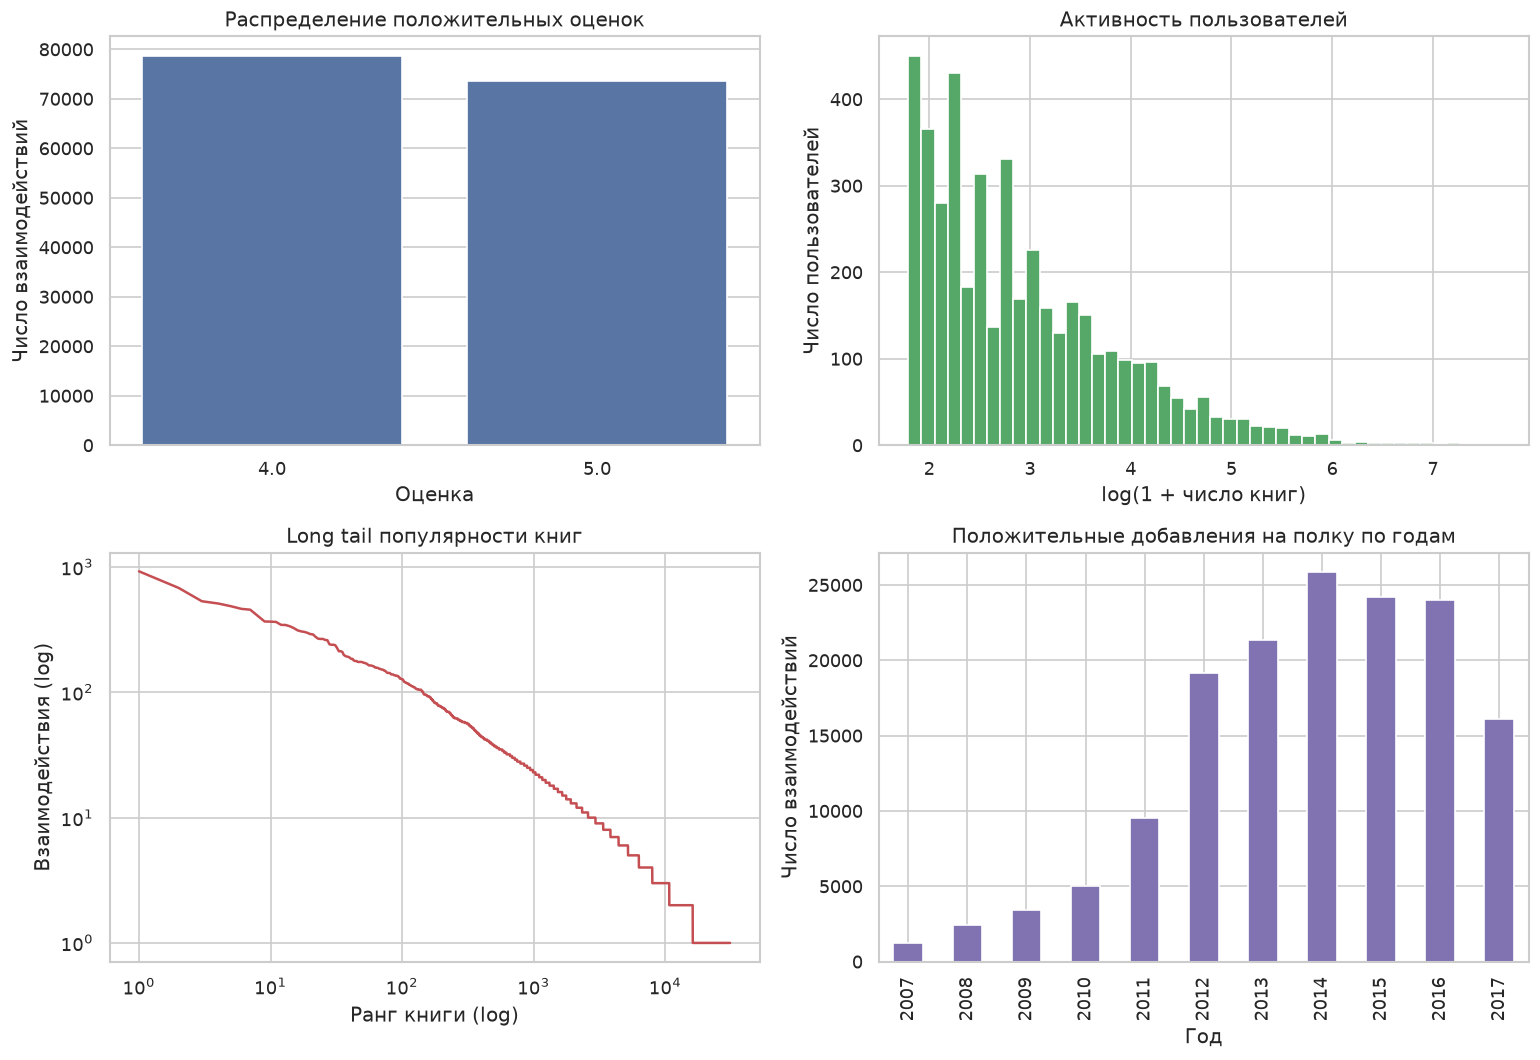

,Метрика,Значение
0,Медиана книг на пользователя,14.000000
1,95-й перцентиль книг на пользователя,119.000000
2,Медиана взаимодействий на книгу,2.000000
3,Доля 10 самых популярных книг,0.034194
4,Разреженность полного user–item пространства,0.998894


Вывод EDA: положительный сигнал имеет long-tail по пользователям и книгам. MostPop поэтому будет сильным baseline на head-каталоге, но потенциально менее новым и менее покрывающим каталог.


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=interactions, x="rating", ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set(title="Распределение положительных оценок", xlabel="Оценка", ylabel="Число взаимодействий")

np.log1p(interactions.groupby("user_id").size()).plot.hist(bins=45, ax=axes[0, 1], color="#55A868")
axes[0, 1].set(title="Активность пользователей", xlabel="log(1 + число книг)", ylabel="Число пользователей")

item_popularity = interactions.groupby("book_id").size().sort_values(ascending=False).reset_index(drop=True)
axes[1, 0].loglog(np.arange(1, len(item_popularity) + 1), item_popularity.values, color="#C44E52")
axes[1, 0].set(title="Long tail популярности книг", xlabel="Ранг книги (log)", ylabel="Взаимодействия (log)")

interactions.assign(year=interactions["shelf_added_at"].dt.year).groupby("year").size().plot.bar(ax=axes[1, 1], color="#8172B2")
axes[1, 1].set(title="Положительные добавления на полку по годам", xlabel="Год", ylabel="Число взаимодействий")
plt.tight_layout()
plt.show()

eda_summary = pd.DataFrame({
    "Метрика": [
        "Медиана книг на пользователя",
        "95-й перцентиль книг на пользователя",
        "Медиана взаимодействий на книгу",
        "Доля 10 самых популярных книг",
        "Разреженность полного user–item пространства",
    ],
    "Значение": [
        float(interactions.groupby("user_id").size().median()),
        float(interactions.groupby("user_id").size().quantile(0.95)),
        float(interactions.groupby("book_id").size().median()),
        float(item_popularity.head(10).sum() / len(interactions)),
        1 - len(interactions) / (interactions["user_id"].nunique() * interactions["book_id"].nunique()),
    ],
})
display(eda_summary)
print("Вывод EDA: положительный сигнал имеет long-tail по пользователям и книгам. MostPop поэтому будет сильным baseline на head-каталоге, но потенциально менее новым и менее покрывающим каталог.")


## 4. Строгий global temporal split, timestamp ties и attrition

Вместо удержания «последней книги каждого пользователя» применяется единый глобальный cutoff $T_{outer}$, близкий к 80-му перцентилю по `date_added`. В train попадают только события строго раньше $T_{outer}$; весь timestamp block $T_{outer}$ и позднее находится в future pool. Поэтому popularity, catalog и модели не получают информацию из будущего ни для одного пользователя.

Для каждого пользователя цель — первая timestamp-группа в future pool. Пользователь оценивается только если эта группа содержит ровно одну книгу; timestamp ties не разрушаются произвольным `book_id`. Каталог фиксируется из outer-train **до** проверки того, попала ли target-книга в него.


In [5]:
OUTER_TRAIN_FRACTION = 0.80
INNER_TRAIN_FRACTION = 0.80


def choose_block_cutoff(events: pd.DataFrame, train_fraction: float) -> pd.Timestamp:
    ordered = events.sort_values(["shelf_added_at", "user_id", "book_id"]).reset_index(drop=True)
    index = min(max(int(np.floor(len(ordered) * train_fraction)), 1), len(ordered) - 1)
    return ordered.loc[index, "shelf_added_at"]


def first_future_targets(future: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    first_time = future.groupby("user_id")["shelf_added_at"].min().rename("first_future_at")
    first_group = future.merge(first_time, left_on="user_id", right_index=True, how="inner")
    first_group = first_group[first_group["shelf_added_at"] == first_group["first_future_at"]].copy()
    basket_sizes = first_group.groupby("user_id")["book_id"].nunique().rename("first_future_books")
    singleton = first_group[first_group["user_id"].map(basket_sizes) == 1].copy()
    return singleton, basket_sizes.to_frame()


def build_global_temporal_split(events: pd.DataFrame, train_fraction: float, catalog_size: int, min_train: int) -> dict[str, object]:
    cutoff = choose_block_cutoff(events, train_fraction)
    train_all = events[events["shelf_added_at"] < cutoff].copy()
    future_all = events[events["shelf_added_at"] >= cutoff].copy()
    singleton_targets, first_future_baskets = first_future_targets(future_all)

    # The catalog and model-fitting cohort depend only on pre-cutoff training data.
    catalog = train_all.groupby("book_id").size().sort_values(ascending=False).head(catalog_size).index.to_numpy()
    catalog_set = set(catalog)
    train_catalog = train_all[train_all["book_id"].isin(catalog_set)].copy()
    prior_counts = train_catalog.groupby("user_id").size()
    fit_user_ids = np.array(sorted(prior_counts[prior_counts >= min_train].index))
    fit_user_set = set(fit_user_ids)
    train = train_catalog[train_catalog["user_id"].isin(fit_user_set)].copy()

    # Future labels select only evaluation rows; they never change X, popularity, or item weights.
    target_in_catalog = singleton_targets[singleton_targets["book_id"].isin(catalog_set)].copy()
    eval_user_ids = np.array(sorted(set(target_in_catalog["user_id"]).intersection(fit_user_set)))
    test = target_in_catalog[target_in_catalog["user_id"].isin(eval_user_ids)].copy()

    item_ids = np.array(sorted(catalog))
    user_to_idx = {user_id: idx for idx, user_id in enumerate(fit_user_ids)}
    item_to_idx = {book_id: idx for idx, book_id in enumerate(item_ids)}
    rows = train["user_id"].map(user_to_idx).to_numpy()
    cols = train["book_id"].map(item_to_idx).to_numpy()
    X = csr_matrix((np.ones(len(train), dtype=np.float64), (rows, cols)), shape=(len(fit_user_ids), len(item_ids)))
    eval_row_indices = np.array([user_to_idx[user_id] for user_id in eval_user_ids], dtype=np.int32)
    targets = test.set_index("user_id").loc[eval_user_ids, "book_id"].map(item_to_idx).to_numpy()

    assert train_all["shelf_added_at"].max() < cutoff <= future_all["shelf_added_at"].min()
    assert (test["shelf_added_at"] >= cutoff).all()
    assert len(test) == len(eval_user_ids) and X.shape[1] == len(item_ids)
    return {
        "cutoff": cutoff, "train_all": train_all, "future_all": future_all,
        "singleton_targets": singleton_targets, "first_future_baskets": first_future_baskets,
        "catalog": catalog, "target_in_catalog": target_in_catalog,
        "train": train, "test": test, "fit_user_ids": fit_user_ids,
        "eval_user_ids": eval_user_ids, "eval_row_indices": eval_row_indices,
        "item_ids": item_ids, "user_to_idx": user_to_idx, "item_to_idx": item_to_idx,
        "X": X, "targets": targets,
    }


outer = build_global_temporal_split(interactions, OUTER_TRAIN_FRACTION, N_CATALOG_ITEMS, MIN_TRAIN_INTERACTIONS)
first_future_users = outer["first_future_baskets"].index
singleton_users = outer["singleton_targets"]["user_id"].unique()
attrition = pd.DataFrame({
    "Этап": [
        "Canonical положительные взаимодействия",
        "Outer train: date_added < T_outer",
        "Future pool: date_added ≥ T_outer",
        "Пользователи с future-взаимодействием",
        "Singleton первая future-группа (без timestamp tie)",
        f"Singleton target в fixed top-{N_CATALOG_ITEMS} outer-train каталоге",
        f"Train-only warm users: ≥{MIN_TRAIN_INTERACTIONS} prior in-catalog книг",
        "Итоговые evaluation users: train-only warm + singleton warm target",
    ],
    "Взаимодействий / целей": [
        len(interactions), len(outer["train_all"]), len(outer["future_all"]), len(first_future_users), len(singleton_users), len(outer["target_in_catalog"]), len(outer["train"]), len(outer["test"]),
    ],
    "Пользователей": [
        interactions["user_id"].nunique(), outer["train_all"]["user_id"].nunique(), outer["future_all"]["user_id"].nunique(), len(first_future_users), len(singleton_users), outer["target_in_catalog"]["user_id"].nunique(), len(outer["fit_user_ids"]), len(outer["eval_user_ids"]),
    ],
})
display(attrition)
tied_users = int((outer["first_future_baskets"]["first_future_books"] > 1).sum())
print(f"T_outer = {outer['cutoff'].isoformat()} (train_fraction target: {OUTER_TRAIN_FRACTION:.0%}); исключено timestamp-tie пользователей: {tied_users:,}.")

X = outer["X"]
train = outer["train"]
test = outer["test"]
user_ids = outer["fit_user_ids"]
eval_user_ids = outer["eval_user_ids"]
eval_row_indices = outer["eval_row_indices"]
item_ids = outer["item_ids"]
test_targets = outer["targets"]
train_popularity = np.asarray(X.sum(axis=0)).ravel()
sparsity = 1 - X.nnz / (X.shape[0] * X.shape[1])
print(f"Итоговая fit-матрица outer-train: {X.shape[0]:,} × {X.shape[1]:,}; разреженность {sparsity:.4%}. Оценка использует {len(eval_user_ids):,} future-label строк.")


,Этап,Взаимодействий / целей,Пользователей
0,Canonical положительные взаимодействия,152161,4432
1,Outer train: date_added < T_outer,121728,4039
2,Future pool: date_added ≥ T_outer,30433,2229
3,Пользователи с future-взаимодействием,2229,2229
4,Singleton первая future-группа (без timestamp ...,2227,2227
5,Singleton target в fixed top-800 outer-train к...,899,899
6,Train-only warm users: ≥3 prior in-catalog книг,47537,3169
7,Итоговые evaluation users: train-only warm + s...,486,486


T_outer = 2016-05-15T00:48:35+00:00 (train_fraction target: 80%); исключено timestamp-tie пользователей: 2.
Итоговая fit-матрица outer-train: 3,169 × 800; разреженность 98.1249%. Оценка использует 486 future-label строк.


## 5. Inner temporal validation и модели

Модели имеют разные роли: **B0 MostPop** — неперсонализированный baseline; **P1 ItemKNN** — локальная item–item персонализация по cosine similarity; **P2 EASE** — глобальная линейная item–item модель. Уже встреченные в outer-train книги исключаются у всех методов.

Гиперпараметр EASE выбирается только по inner global temporal validation внутри outer-train. Final outer test для выбора λ не используется.


In [6]:
def mask_seen(scores: np.ndarray, seen: csr_matrix) -> np.ndarray:
    masked = scores.copy()
    masked[seen.nonzero()] = -np.inf
    return masked


def top_k(scores: np.ndarray, k: int) -> np.ndarray:
    n_users, n_items = scores.shape
    if k > n_items:
        raise ValueError("k cannot exceed the candidate catalog")
    result = np.empty((n_users, k), dtype=np.int32)
    item_index = np.arange(n_items)
    for user_idx in range(n_users):
        result[user_idx] = np.lexsort((item_index, -scores[user_idx]))[:k]
    return result


def rank_of_target(recommendations: np.ndarray, targets: np.ndarray) -> np.ndarray:
    matches = recommendations == targets[:, None]
    return np.where(matches.any(axis=1), matches.argmax(axis=1) + 1, 0)


def ndcg_at_k(recommendations: np.ndarray, targets: np.ndarray) -> float:
    ranks = rank_of_target(recommendations, targets)
    gains = np.zeros_like(ranks, dtype=float)
    hit = ranks > 0
    gains[hit] = 1 / np.log2(ranks[hit] + 1)
    return float(gains.mean())


def recommend_most_pop(X: csr_matrix, popularity: np.ndarray, k: int) -> np.ndarray:
    scores = np.broadcast_to(popularity, (X.shape[0], len(popularity))).astype(float).copy()
    return top_k(mask_seen(scores, X), k)


def item_cosine_similarity(X: csr_matrix) -> np.ndarray:
    item_vectors = normalize(X.T, norm="l2", axis=1)
    similarity = (item_vectors @ item_vectors.T).toarray()
    np.fill_diagonal(similarity, 0.0)
    return similarity


def recommend_item_knn(X: csr_matrix, similarity: np.ndarray, k: int) -> np.ndarray:
    return top_k(mask_seen(np.asarray(X @ similarity), X), k)


def ease_weights(X: csr_matrix, l2: float) -> np.ndarray:
    dense_x = X.toarray().astype(float)
    gram = dense_x.T @ dense_x
    gram.flat[:: gram.shape[0] + 1] += l2
    precision = np.linalg.inv(gram)
    weights = -precision / np.diag(precision)
    np.fill_diagonal(weights, 0.0)
    return weights


def recommend_ease(X: csr_matrix, l2: float, k: int) -> tuple[np.ndarray, np.ndarray]:
    weights = ease_weights(X, l2)
    scores = X.toarray().astype(float) @ weights
    return top_k(mask_seen(scores, X), k), weights


# The inner cutoff and all its catalogs/eligibility rules use outer-train only.
inner = build_global_temporal_split(outer["train_all"], INNER_TRAIN_FRACTION, N_CATALOG_ITEMS, MIN_TRAIN_INTERACTIONS)
validation_rows = []
for candidate in EASE_CANDIDATES:
    recs, _ = recommend_ease(inner["X"], candidate, K)
    validation_rows.append({"lambda": candidate, "NDCG@10 (inner validation)": ndcg_at_k(recs[inner["eval_row_indices"]], inner["targets"])})
validation = pd.DataFrame(validation_rows).sort_values(["NDCG@10 (inner validation)", "lambda"], ascending=[False, True]).reset_index(drop=True)
BEST_EASE_LAMBDA = float(validation.iloc[0]["lambda"])
display(validation)
print(f"T_inner = {inner['cutoff'].isoformat()}; выбрана λ={BEST_EASE_LAMBDA:g}; outer test не использовался при выборе.")

item_similarity = item_cosine_similarity(X)
most_pop_recs_all = recommend_most_pop(X, train_popularity, K)
item_knn_recs_all = recommend_item_knn(X, item_similarity, K)
ease_recs_all, _ = recommend_ease(X, BEST_EASE_LAMBDA, K)
# Slice only after fitting on the train-only cohort; future labels select evaluation rows only.
most_pop_recs = most_pop_recs_all[eval_row_indices]
item_knn_recs = item_knn_recs_all[eval_row_indices]
ease_recs = ease_recs_all[eval_row_indices]


,lambda,NDCG@10 (inner validation)
0,100.0,0.132319
1,50.0,0.129841
2,300.0,0.129676
3,600.0,0.124460
4,1000.0,0.122759


T_inner = 2015-05-21T03:21:14+00:00; выбрана λ=100; outer test не использовался при выборе.


## 6. Метрики и итоговая оценка на outer test

У каждого пользователя одна hidden target-книга. Поэтому `Recall@10` здесь равен HitRate@10. `NDCG@10` и `MRR@10` учитывают позицию цели. `Novelty@10` — средняя информационная неожиданность рекомендаций относительно train-популярности; `Diversity@10` — средняя попарная cosine-непохожесть в списке; `Coverage@10` — доля каталога, показанная хотя бы одному пользователю.

,Ожидаемый компромисс,Recall@10,NDCG@10,MRR@10,Novelty@10,Diversity@10,Coverage@10
Модель,,,,,,,
B0 MostPop,"Популярность: точный, но head-biased baseline",0.1296,0.0769,0.0603,6.9425,0.7665,0.0338
P1 ItemKNN,Локальная персонализация по соседним книгам,0.2243,0.1315,0.1037,8.6821,0.6851,0.6525
P2 EASE (λ=100),Глобальные регуляризованные item–item веса,0.2634,0.1555,0.1224,8.5630,0.7937,0.6988


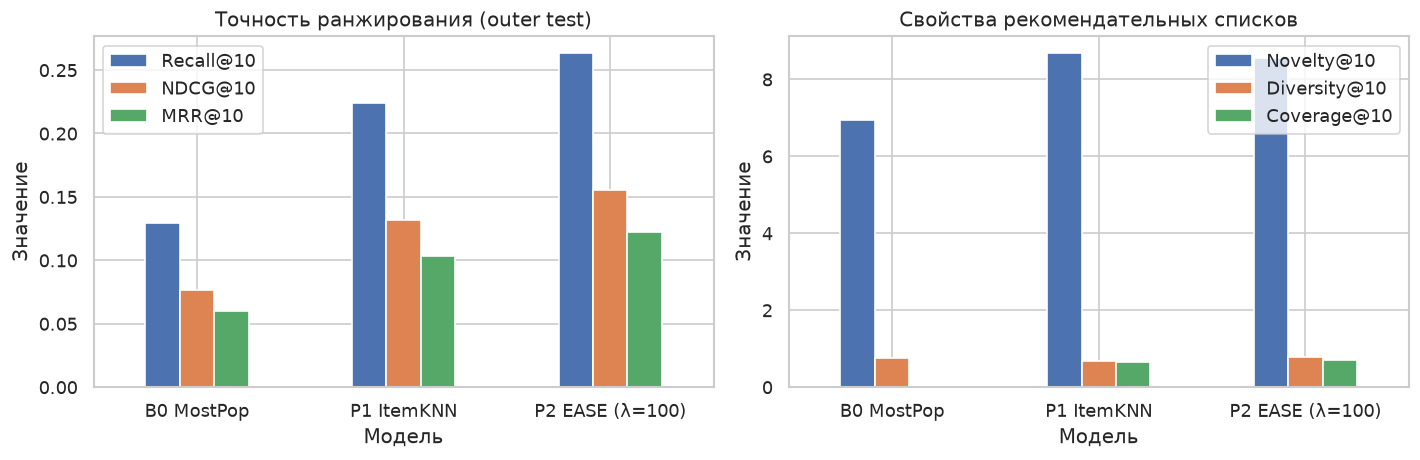

NDCG@10: P2 EASE (λ=100) (0.1555); novelty: P1 ItemKNN; diversity: P2 EASE (λ=100); coverage: P2 EASE (λ=100).


,Сравнение с B0 MostPop,Δ Recall@10,95% CI Δ Recall@10,Δ NDCG@10,95% CI Δ NDCG@10
0,P1 ItemKNN,0.0947,"[0.0473, 0.1420]",0.0545,"[0.0245, 0.0883]"
1,P2 EASE (λ=100),0.1337,"[0.0844, 0.1852]",0.0785,"[0.0467, 0.1135]"


Bootstrap-интервал, не пересекающий 0, поддерживает преимущество над MostPop в данном warm/head offline protocol; это не является оценкой cold-start или онлайн-эффекта.


In [7]:
def evaluate(recommendations: np.ndarray, targets: np.ndarray, popularity: np.ndarray, similarity: np.ndarray) -> dict[str, float]:
    ranks = rank_of_target(recommendations, targets)
    hit = ranks > 0
    safe_ranks = np.maximum(ranks, 1)
    p = np.maximum(popularity / popularity.sum(), 1 / popularity.sum())
    novelty = -np.log2(p[recommendations]).mean()
    diversity = []
    for recs in recommendations:
        pair_similarities = [similarity[i, j] for i, j in combinations(recs, 2)]
        diversity.append(1 - float(np.mean(pair_similarities)))
    return {
        "Recall@10": float(hit.mean()),
        "NDCG@10": float(np.where(hit, 1 / np.log2(safe_ranks + 1), 0).mean()),
        "MRR@10": float(np.where(hit, 1 / safe_ranks, 0).mean()),
        "Novelty@10": float(novelty),
        "Diversity@10": float(np.mean(diversity)),
        "Coverage@10": float(np.unique(recommendations).size / len(popularity)),
    }

model_specs = [
    ("B0 MostPop", "Популярность: точный, но head-biased baseline", most_pop_recs),
    ("P1 ItemKNN", "Локальная персонализация по соседним книгам", item_knn_recs),
    (f"P2 EASE (λ={BEST_EASE_LAMBDA:g})", "Глобальные регуляризованные item–item веса", ease_recs),
]
metrics = pd.DataFrame([
    {"Модель": name, "Ожидаемый компромисс": hypothesis, **evaluate(recs, test_targets, train_popularity, item_similarity)}
    for name, hypothesis, recs in model_specs
]).set_index("Модель")
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics[["Recall@10", "NDCG@10", "MRR@10"]].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Точность ранжирования (outer test)", ylabel="Значение")
metrics[["Novelty@10", "Diversity@10", "Coverage@10"]].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Свойства рекомендательных списков", ylabel="Значение")
plt.tight_layout()
plt.show()

best_accuracy = metrics["NDCG@10"].idxmax()
best_novelty = metrics["Novelty@10"].idxmax()
best_diversity = metrics["Diversity@10"].idxmax()
best_coverage = metrics["Coverage@10"].idxmax()
print(
    f"NDCG@10: {best_accuracy} ({metrics.loc[best_accuracy, 'NDCG@10']:.4f}); "
    f"novelty: {best_novelty}; diversity: {best_diversity}; coverage: {best_coverage}."
)

# Paired bootstrap: uncertainty of the two personalized methods relative to MostPop.
def per_user_ranking_scores(recommendations: np.ndarray, targets: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    ranks = rank_of_target(recommendations, targets)
    recall = (ranks > 0).astype(float)
    ndcg = np.zeros_like(ranks, dtype=float)
    hit = ranks > 0
    ndcg[hit] = 1 / np.log2(ranks[hit] + 1)
    return recall, ndcg


def paired_bootstrap_ci(delta: np.ndarray, seed: int = SEED, n_bootstrap: int = 2000) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(delta), size=(n_bootstrap, len(delta)))
    estimates = delta[draws].mean(axis=1)
    return tuple(np.quantile(estimates, [0.025, 0.975]))

baseline_recall, baseline_ndcg = per_user_ranking_scores(most_pop_recs, test_targets)
comparison_rows = []
for name, _, recs in model_specs[1:]:
    recall, ndcg = per_user_ranking_scores(recs, test_targets)
    recall_ci = paired_bootstrap_ci(recall - baseline_recall)
    ndcg_ci = paired_bootstrap_ci(ndcg - baseline_ndcg)
    comparison_rows.append({
        "Сравнение с B0 MostPop": name,
        "Δ Recall@10": float((recall - baseline_recall).mean()),
        "95% CI Δ Recall@10": f"[{recall_ci[0]:.4f}, {recall_ci[1]:.4f}]",
        "Δ NDCG@10": float((ndcg - baseline_ndcg).mean()),
        "95% CI Δ NDCG@10": f"[{ndcg_ci[0]:.4f}, {ndcg_ci[1]:.4f}]",
    })
bootstrap_comparison = pd.DataFrame(comparison_rows)
display(bootstrap_comparison.round({"Δ Recall@10": 4, "Δ NDCG@10": 4}))
print("Bootstrap-интервал, не пересекающий 0, поддерживает преимущество над MostPop в данном warm/head offline protocol; это не является оценкой cold-start или онлайн-эффекта.")


## 7. Диагностические примеры рекомендаций

Ниже для трёх фиксированно выбранных пользователей показаны последние книги из outer-train истории, первая singleton future target и top-$5$ каждой модели. Это не доказательство среднего качества, а проверка понятности и различий между ранжированиями.


In [8]:
def load_book_metadata(path: Path, wanted_ids: set[str]) -> pd.DataFrame:
    found = []
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            book = json.loads(line)
            book_id = str(book.get("book_id", ""))
            if book_id in wanted_ids:
                authors = ", ".join(a.get("name", "") for a in book.get("authors", []) if a.get("name"))
                found.append({"book_id": book_id, "title": book.get("title", ""), "authors": authors})
    return pd.DataFrame(found).drop_duplicates("book_id")

# One EASE hit, one EASE miss, then the first remaining user: deterministic diagnostic selection.
ease_ranks = rank_of_target(ease_recs, test_targets)
hit_idx = np.flatnonzero(ease_ranks > 0)
miss_idx = np.flatnonzero(ease_ranks == 0)
selected_indices = []
for group in (hit_idx, miss_idx, np.arange(len(eval_user_ids))):
    for idx in group:
        if int(idx) not in selected_indices:
            selected_indices.append(int(idx))
            break
selected_indices = selected_indices[:3]

wanted_ids = set(item_ids)
for idx in selected_indices:
    user = eval_user_ids[idx]
    wanted_ids.update(outer["train_all"].loc[outer["train_all"]["user_id"] == user, "book_id"].tail(5))
metadata = load_book_metadata(BOOKS_PATH, wanted_ids)
name_by_id = metadata.set_index("book_id").apply(
    lambda row: f"{row['title']} — {row['authors']}" if row["authors"] else row["title"], axis=1
).to_dict()


def book_name(book_id: str) -> str:
    return name_by_id.get(book_id, f"book_id={book_id}")

recommendation_sets = {name: recs for name, _, recs in model_specs}
diagnostic_rows = []
for idx in selected_indices:
    user = eval_user_ids[idx]
    history_ids = outer["train_all"].loc[outer["train_all"]["user_id"] == user].sort_values(["shelf_added_at", "book_id"]).tail(5)["book_id"]
    target = item_ids[test_targets[idx]]
    row = {
        "Пользователь": user[:10] + "…",
        "Последние 5 книг outer-train": "<br>".join(book_name(book_id) for book_id in history_ids),
        "Singleton future target": book_name(target),
    }
    for model_name, recommendations in recommendation_sets.items():
        rank = rank_of_target(recommendations[idx:idx+1], test_targets[idx:idx+1])[0]
        row[model_name] = "<br>".join(book_name(item_ids[item_idx]) for item_idx in recommendations[idx, :5]) + f"<br><b>rank target: {rank if rank else 'miss'}</b>"
    diagnostic_rows.append(row)
display(pd.DataFrame(diagnostic_rows))


,Пользователь,Последние 5 книг outer-train,Singleton future target,B0 MostPop,P1 ItemKNN,P2 EASE (λ=100)
0,0294431fb7…,"Batman, Volume 3: Death of the Family<br>Batma...","Batman, Volume 2: The City of Owls","Watchmen<br>Saga, Vol. 1 (Saga, #1)<br>V for V...","Batman, Volume 2: The City of Owls<br>Batman: ...","Batman, Volume 2: The City of Owls<br>Batman: ..."
1,01d504e19f…,There's Treasure Everywhere: A Calvin and Hobb...,Roller Girl,"Watchmen<br>Saga, Vol. 1 (Saga, #1)<br>Maus I:...",Watchmen<br>Batman: The Dark Knight Returns (T...,Watchmen<br>Batman: The Dark Knight Returns (T...
2,029ed916d4…,"Chew, Vol. 4: Flambé<br>Captain Marvel, Volume...","Saga, Vol. 6 (Saga, #6)",Watchmen<br>V for Vendetta<br>Preludes & Noctu...,"Rat Queens, Vol. 1: Sass & Sorcery<br>Sex Crim...","Sex Criminals, Vol. 1: One Weird Trick<br>Rat ..."


## 8. Ограничения, улучшения и вывод

### Ограничения

1. **Семантика времени.** `date_added` — timestamp наблюдаемого появления shelf-записи, а не подтверждённая дата завершения чтения. Поля `read_at` и `date_updated` сознательно не используются для создания temporal order.
2. **Warm/head evaluation.** Пользователи без достаточной pre-cutoff истории, singleton future targets вне fixed top-800 каталога и timestamp ties исключены. Метрики нельзя переносить на cold-start и весь long tail.
3. **Неявная обратная связь.** Отсутствие положительной записи не означает негативную реакцию; offline ranking не измеряет реальное удовлетворение.
4. **Масштабирование.** EASE обращает матрицу размера `n_items × n_items`; на полном каталоге нужны ALS/BPR, approximate nearest neighbours или двухэтапное candidate generation + ranking.
5. **Оффлайн и продукт.** Даже строгий temporal protocol не заменяет online A/B-тест с guardrail-метриками: скрытия, разнообразие потребления, retention.

### Возможные улучшения

- rolling-origin validation и несколько global temporal folds;
- настройка ItemKNN и EASE по нескольким temporal folds;
- контентные признаки книги (автор, жанр, описание) для cold-start;
- multi-relevant-item basket evaluation для пользователей с tied first-future timestamp;
- sampled negatives, pairwise ranking loss и разнообразие как ограничение reranking;
- online A/B-тест после offline-проверки.

### Вывод

Построен воспроизводимый эксперимент для персональных top-$10$ рекомендаций книг. До моделирования выполнен потоковый аудит исходных данных; версия файлов закреплена SHA-256 manifest. Global outer test отделяет все train-взаимодействия от future pool строгой границей `date_added`, а λ EASE подбирается на отдельной inner global temporal validation. Сравнены **B0 MostPop**, **P1 ItemKNN** и **P2 EASE** по трём ranking-метрикам и трём recommendation-specific метрикам. Результаты относятся к предсказанию первой singleton future positive shelf addition среди warm users на fixed head-каталоге, а не к завершению чтения или универсальному качеству для всех книг и пользователей.

## Источники

1. [UCSD Book Graph / Goodreads: описание набора и статистика](https://mcauleylab.ucsd.edu/public_datasets/gdrive/goodreads/UCSD%20Book%20Graph.html), дата обращения: 19 октября 2026.
2. Wan, M., McAuley, J. [Item Recommendation on Monotonic Behavior Chains](https://cseweb.ucsd.edu/~jmcauley/pdfs/recsys18.pdf), RecSys 2018.
3. Steck, H. [Embarrassingly Shallow Autoencoders for Sparse Data](https://arxiv.org/abs/1905.03375), WWW 2019.
4. [Лицензионные условия и исходные URL фиксированной версии](data_manifest.json).
